# Where does a quantum PDE solver survive on spin qubits? (INSTRUCTOR (solutions))
**Hands-on exercise, 20 min** (part of the 2 h masterclass)

**Setting.** A toy single-mode problem from the Kolmogorian/LCHS framework (Bravyi et al., arXiv:2606.08349): the cubic coupling operator
$C = J\,(a^{\dagger 2}a - a^{\dagger}a^{2})$ in a Fock space truncated at dimension $D$.
We ask three questions a resource estimator must answer on *noisy spin qubits*:

| Part | Time | Question |
|---|---|---|
| 1 | ~6 min | Binary (log₂D qubits) vs. unary (D qubits) encoding: how many two-qubit gates? |
| 2 | ~5 min | How much purity survives under spin-qubit noise (SpinPulse), measured vs. modeled? |
| 3 | ~6 min | Which (x₀, q) problem instances are feasible on a NISQ spin device? |
| – | ~3 min | Debrief |

**How to work.** Cells marked `# TODO` need your code. Replace every `___`. Cells starting with `CHECK` tell you whether you are right.
Everything runs in seconds: expensive SpinPulse simulations were precomputed (their numbers are in the data cell).

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.special import gammaln
from numpy.polynomial.hermite_e import hermeval
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

def check(name, ok, hint=""):
    print(("PASS  " if ok else "FAIL  ") + name + ("" if ok else f"   hint: {hint}"))

# ---- precomputed results (SpinPulse, PINK noise, T2S=8000, J=0.15, t=1, 4 Trotter steps) ----
D_LIST  = [2, 4, 8, 16]
GATES   = {"binary": [0, 6, 172, 680], "unary": [0, 32, 96, 224]}   # two-qubit gates after transpilation
PURITY  = {  # (value, method): 'measured' = full SpinPulse simulation, 'modeled' = exp(-c * gates)
    "binary": [(1.00, "measured"), (1.00, "measured"), (0.93, "measured"), (0.33, "measured")],
    "unary":  [(1.00, "measured"), (1.00, "measured"), (0.88, "modeled"),  (0.73, "modeled")],
}
C_FIT = 0.00139   # fitted: purity ~ exp(-C_FIT * n_2q)

## Part 1 (~6 min): binary vs. unary encoding
In the **binary** encoding Fock level $n$ is stored as the bit string of $n$ (log₂D qubits).
In the **unary** (one-hot) encoding level $n$ means "qubit $n$ is excited" (D qubits).

**1a. Build $C$ and look at its structure.**

In [2]:
def annihilation(D):
    a = np.zeros((D, D))
    for n in range(1, D): a[n-1, n] = np.sqrt(n)
    return a

def build_C(D, J=0.15):
    a = annihilation(D); ad = a.T
    raw = ad @ ad @ a - ad @ a @ a
    return J * (raw - raw.T) / 2.0

C8 = build_C(8)
np.set_printoptions(precision=2, suppress=True, linewidth=140)
print(C8)

[[ 0.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.   -0.21  0.    0.    0.    0.    0.  ]
 [ 0.    0.21  0.   -0.52  0.    0.    0.    0.  ]
 [ 0.    0.    0.52  0.   -0.9   0.    0.    0.  ]
 [ 0.    0.    0.    0.9   0.   -1.34  0.    0.  ]
 [ 0.    0.    0.    0.    1.34  0.   -1.84  0.  ]
 [ 0.    0.    0.    0.    0.    1.84  0.   -2.38]
 [ 0.    0.    0.    0.    0.    0.    2.38  0.  ]]


In [3]:
nonzero_offsets = [k for k in range(-7, 8) if np.any(np.abs(np.diag(C8, k)) > 1e-12)]
print("nonzero offsets:", nonzero_offsets)

nonzero offsets: [-1, 1]


In [4]:
try:
    check("C couples ONLY neighbouring Fock levels (offsets -1, +1)", sorted(nonzero_offsets) == [-1, 1],
          "look at the printed matrix: which diagonals are filled?")
except Exception as e: print("TODO not finished:", e)
print("D=2 coupling is identically zero:", np.allclose(build_C(2), 0), "  <- a truncation artefact, so 0 gates at D=2")

PASS  C couples ONLY neighbouring Fock levels (offsets -1, +1)
D=2 coupling is identically zero: True   <- a truncation artefact, so 0 gates at D=2


**Why this matters.** Neighbour-only coupling means in the unary encoding $e^{Ct}$ becomes a chain of *local* hopping (XY/Givens) gates between adjacent qubits:
one gate per $|n\rangle \leftrightarrow |n{+}1\rangle$ link, i.e. $D-1$ gates per Trotter step. In the binary encoding the same operator
needs non-local bit-flip cascades (many multi-qubit Pauli strings).

**1b. Prediction (write it down before running):** at what D does unary become cheaper than binary in two-qubit gates?
Your guess: `D = ____`

**1c. Now compute it from the data.**

In [5]:
b = np.array(GATES["binary"], float); u = np.array(GATES["unary"], float)
ratio = {D: bi/ui for D, bi, ui in zip(D_LIST, b, u) if ui > 0}
crossover_D = min(D for D, r in ratio.items() if r > 1)
print("binary/unary ratio:", {k: round(v, 2) for k, v in ratio.items()})
print("crossover D:", crossover_D)

binary/unary ratio: {4: np.float64(0.19), 8: np.float64(1.79), 16: np.float64(3.04)}
crossover D: 8


In [6]:
p_binary = np.log(680/172) / np.log(2)
p_unary  = np.log(224/96) / np.log(2)
print(f"binary ~ D^{p_binary:.2f}   unary ~ D^{p_unary:.2f}")

binary ~ D^1.98   unary ~ D^1.22


PASS  crossover at D=8
PASS  binary scales roughly quadratically (p in 1.7..2.3)
PASS  unary scales roughly linearly (p in 0.8..1.5)


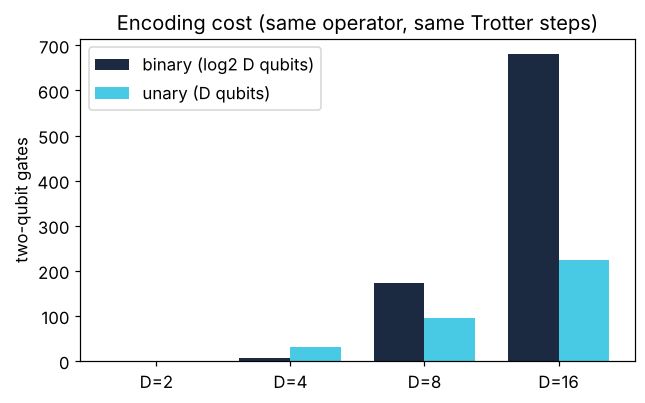

In [7]:
try:
    check("crossover at D=8", crossover_D == 8, "first D where binary/unary > 1")
    check("binary scales roughly quadratically (p in 1.7..2.3)", 1.7 < p_binary < 2.3)
    check("unary scales roughly linearly (p in 0.8..1.5)", 0.8 < p_unary < 1.5)
except Exception as e: print("TODO not finished:", e)

x = np.arange(len(D_LIST)); w = 0.38
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(x-w/2, GATES["binary"], w, label="binary (log2 D qubits)", color="#1b2a41")
ax.bar(x+w/2, GATES["unary"],  w, label="unary (D qubits)",       color="#48cae4")
ax.set_xticks(x); ax.set_xticklabels([f"D={d}" for d in D_LIST]); ax.set_ylabel("two-qubit gates")
ax.legend(); ax.set_title("Encoding cost (same operator, same Trotter steps)"); plt.tight_layout(); plt.show()

**Discussion (1 min):** unary needs D qubits instead of log₂D. For D=16 that is 16 vs. 4 qubits.
Why can paying exponentially more qubits still be the better deal on spin qubits? (Think: which resource does noise punish?)

## Part 2 (~5 min): purity under spin-qubit noise
Purity $\mathrm{Tr}(\rho^2)$ equals 1 for a pure state and drops toward $1/2^{n}$ for a fully mixed one. SpinPulse gives us the noisy channel for PINK (1/f) noise.
Dense simulation costs $16^{n_\text{qubits}}$ memory, so we could only **measure** up to 7 qubits. Beyond that we **model**:
$$\text{purity} \approx \exp(-c\,n_{2q}),\qquad c = 0.00139\ \text{(fitted)}.$$

**2a. Hand calculation.** Unary at D=8 has 96 two-qubit gates. What purity does the model predict?

In [8]:
purity_model = lambda n2q: np.exp(-C_FIT * n2q)
print("unary D=8 :", round(purity_model(96), 3))
print("unary D=16:", round(purity_model(224), 3))

unary D=8 : 0.875
unary D=16: 0.732


In [9]:
try: check("unary D=8 -> 0.88", abs(purity_model(96) - 0.875) < 0.01)
except Exception as e: print("TODO not finished:", e)

PASS  unary D=8 -> 0.88


**2b. Is the model trustworthy?** We can test it on binary, where we *measured* all four points.
Compute the modeled purity for every binary point and compare to the measurement.

In [10]:
meas  = np.array([p for p, m in PURITY["binary"]])
model = np.array([purity_model(g) for g in GATES["binary"]])
dev = np.abs(meas - model)
for D, a, bm in zip(D_LIST, meas, model): print(f"D={D:2d}  measured {a:.2f}   modeled {bm:.2f}")
print("max deviation:", dev.max().round(2), "at D =", D_LIST[int(dev.argmax())])

D= 2  measured 1.00   modeled 1.00
D= 4  measured 1.00   modeled 0.99
D= 8  measured 0.93   modeled 0.79
D=16  measured 0.33   modeled 0.39
max deviation: 0.14 at D = 8


PASS  you found the largest deviation (~0.15 at D=8)


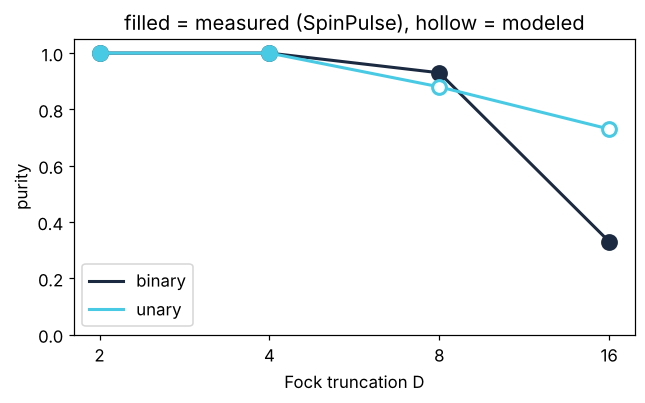

In [11]:
try: check("you found the largest deviation (~0.15 at D=8)", 0.1 < dev.max() < 0.2)
except Exception as e: print("TODO not finished:", e)

fig, ax = plt.subplots(figsize=(6, 3.8))
for enc, col in [("binary", "#1b2a41"), ("unary", "#48cae4")]:
    vals = [p for p, m in PURITY[enc]]
    ax.plot(D_LIST, vals, "-", color=col, lw=2, label=enc)
    for D, (p, m) in zip(D_LIST, PURITY[enc]):
        ax.plot(D, p, "o", color=col, mfc=col if m == "measured" else "white", ms=9, mew=2)
ax.set_xscale("log", base=2); ax.set_xticks(D_LIST); ax.set_xticklabels(D_LIST)
ax.set_xlabel("Fock truncation D"); ax.set_ylabel("purity"); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title("filled = measured (SpinPulse), hollow = modeled"); plt.tight_layout(); plt.show()

**2c. Interpret honestly (write 2 sentences).**
At D=8 binary was *measured* at 0.93 and unary only *modeled* at 0.88: which encoding wins there?
Where is the **purity** crossover (it need not coincide with the gate-count crossover)?

> **Instructor answer.** At D=8 the unary gate count is lower (96 vs 172) but the binary measurement (0.93) is above the modeled unary value (0.88); the model is also pessimistic for binary there (0.79 modeled vs 0.93 measured), so the modeled unary point is probably pessimistic too and the comparison at D=8 is **inconclusive**.
> The purity crossover lies between D=8 and D=16, where unary (0.73, modeled) clearly beats binary (0.33, measured). Take-away: "unary wins for D ≳ 8" is supported for **gate count**, but for **purity** only the D=16 statement is solid. Measured values also fluctuate between runs (5 noise samples).

## Part 3 (~6 min): toy-model feasibility map (NISQ spin qubits)
A grid point $(x_0, q)$ is feasible if **(a)** a truncation $D=2^n$ with small enough $n$ reaches the target accuracy $\varepsilon$ **and** **(b)** the purity at that $n$ stays above a threshold.
For this single-mode problem the algorithmic difficulty depends only on the reduced variable
$$y_0 = x_0\sqrt{2\lambda/q}.$$

In [12]:
LAM, J, T, EPS = 1.0, 0.15, 1.0, 1e-2
X0 = [0.3, 0.6, 1.0, 1.6, 2.5, 4.0]
Q  = [4.0, 1.5, 0.6, 0.25, 0.1, 0.04]
nan = np.nan
# minimal qubit count n (D = 2^n) per (q row, x0 column); NaN = not reachable with n <= 4
GRID_N = np.array([[2,2,2,1,2,2],[2,2,1,2,2,3],[2,1,2,2,3,4],[1,2,2,3,4,nan],[1,2,3,4,nan,nan],[2,3,4,nan,nan,nan]])
PURITY_N = {1: 1.0, 2: 0.9998, 3: 0.846, 4: 0.411}      # SpinPulse purity vs. qubit count at T2S=8000

# --- algorithmic side (provided): recompute any cell yourself in milliseconds ---
def _hermite(n, y):
    c = np.zeros(n+1); c[n] = 1.0
    h = hermeval(y, c); s = np.sign(h) if h != 0 else 1.0
    return float(s*np.exp(np.log(abs(h)+1e-300) - 0.5*gammaln(n+1)))
def v_obs(D, x0, q, lam=LAM, J=J, t=T):
    a = annihilation(D); ad = a.T; raw = ad@ad@a - ad@a@a
    Cm = J*(raw-raw.T)/2; H = -lam*np.diag(np.arange(D)) + Cm
    phi0 = np.zeros(D); phi0[1] = np.sqrt(q/(2*lam))
    y0 = x0*np.sqrt(2*lam/q)
    return float(np.array([_hermite(n, y0) for n in range(D)]) @ expm(H*t) @ phi0)
def n_min(x0, q, eps=EPS, cands=(1,2,3,4), D_ref=128):
    ref = v_obs(D_ref, x0, q)
    for n in cands:
        if abs(v_obs(2**n, x0, q) - ref) < eps: return n
    return nan

**3a. Verify the algorithmic side.** Recompute the cell $(x_0, q)=(2.5, 0.25)$ and compare with the table.

In [13]:
i, j = Q.index(0.25), X0.index(2.5)
print("table:", GRID_N[i, j], "  recomputed:", n_min(2.5, 0.25))

table: 4.0   recomputed: 4


**3b. Feasibility map.** Mark a cell feasible if its $n$ exists and `PURITY_N[n] >= threshold`.

In [14]:
threshold = 0.5
feasible = np.array([[ (not np.isnan(n)) and PURITY_N[int(n)] >= threshold for n in row] for row in GRID_N])
print("feasible cells:", int(feasible.sum()), "of", feasible.size)

feasible cells: 26 of 36


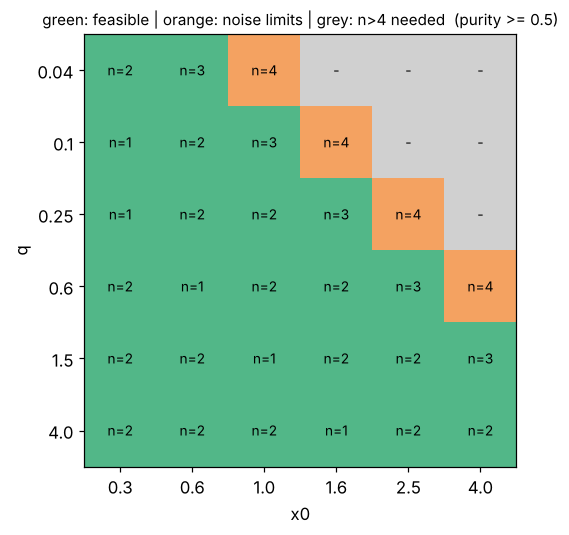

In [15]:
def draw_map(grid_n, feasible, title):
    fig, ax = plt.subplots(figsize=(6.2, 5))
    img = np.where(np.isnan(grid_n), 0, np.where(feasible, 2, 1))     # 0 grey, 1 orange (noise), 2 green
    ax.imshow(img, cmap=plt.matplotlib.colors.ListedColormap(["#d0d0d0", "#f4a261", "#52b788"]), vmin=0, vmax=2, origin="lower")
    for i in range(len(Q)):
        for j in range(len(X0)):
            ax.text(j, i, "-" if np.isnan(grid_n[i, j]) else f"n={int(grid_n[i, j])}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(X0))); ax.set_xticklabels(X0); ax.set_yticks(range(len(Q))); ax.set_yticklabels(Q)
    ax.set_xlabel("x0"); ax.set_ylabel("q"); ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.show()
try: draw_map(GRID_N, feasible, f"green: feasible | orange: noise limits | grey: n>4 needed  (purity >= {threshold})")
except Exception as e: print("TODO not finished:", e)

**3c. Prediction, then test.** Lower the threshold to 0.3, then raise it to 0.9. Which cells change colour, and why?
Which problems need $n=4$? (Hint: compute $y_0$ for them.)

In [16]:
for thr in [0.3, 0.5, 0.9]:
    blocked = [(X0[j], Q[i], int(GRID_N[i, j])) for i in range(len(Q)) for j in range(len(X0))
               if not np.isnan(GRID_N[i, j]) and PURITY_N[int(GRID_N[i, j])] < thr]
    print(f"threshold {thr}: {len(blocked)} blocked cells; n values involved: {sorted(set(b[2] for b in blocked))}")

threshold 0.3: 0 blocked cells; n values involved: []
threshold 0.5: 4 blocked cells; n values involved: [4]
threshold 0.9: 9 blocked cells; n values involved: [3, 4]


In [17]:
y0 = np.array([[X0[j]*np.sqrt(2*LAM/Q[i]) for j in range(len(X0))] for i in range(len(Q))])
for lo, hi in [(0, 2), (2, 4), (4, 6), (6, 10)]:
    m = (y0 >= lo) & (y0 < hi) & ~np.isnan(GRID_N)
    print(f"y0 in [{lo},{hi}):  n values = {sorted(set(int(v) for v in GRID_N[m]))}")

y0 in [0,2):  n values = [1, 2]
y0 in [2,4):  n values = [2]
y0 in [4,6):  n values = [3]
y0 in [6,10):  n values = [4]


> **Instructor answers.** Threshold 0.3: all reachable cells feasible (n=4 purity 0.41 passes). Threshold 0.5: the n=4 cells (y₀ ≈ 7) are blocked by noise. Threshold 0.9: n=3 cells (purity 0.85) are blocked too. Higher y₀ means larger required Fock truncation D, hence more qubits and more gates, hence lower purity: the boundary is a line of constant y₀ in the (x₀, q) plane, cut off by the hardware purity floor.

**3e (bonus, if time).** Change `EPS` (e.g. 1e-3) and recompute a few cells with `n_min`. Does the feasible region grow or shrink?
Then think: the whole analysis used one bosonic mode and illustrative parameters (J=0.15, T2S=8000 a.u.). What would change for the real multi-mode problem?

## Debrief (~3 min)
1. **Structure beats brute force:** C is tridiagonal, so unary turns it into local gates; gate-count crossover at D=8.
2. **Noise punishes gate count, not qubit count** (in this regime): purity ≈ exp(−0.00139·n₂q).
3. **Know what was measured:** measured up to 7 qubits, modeled beyond; model deviations of ~0.15 exist; run-to-run fluctuations too.
4. **Feasibility is two conditions:** algorithmic reach (set by y₀) *and* a hardware purity floor.

*Optional (needs `qiskit` + `spin_pulse`):* the original scripts `unary_vs_binary_combined.py` and `spin_qubit_phase_diagram.py` regenerate all precomputed data.